In [45]:
from pathlib import Path

import harp.data
import matplotlib.pyplot as plt
from harp.device import schema

# LED example analysis

In [46]:
# path = Path("../output/led/hhmmss")

In [47]:
# behavior = schema.create_device_module((path / "device.yml").read_bytes())
# reader = harp.data.open_dataset(path, behavior)
# di = reader.read("DigitalInputState", demux_bit_masks=True)

In [48]:
# plt.plot(di.index, di["DI0"])

# Play sound example analysis

In [49]:
# path = Path("../output/play/hhmmss")

In [50]:
# soundcard = schema.create_device_module((path / "device.yml").read_bytes())
# reader = harp.data.open_dataset(path, soundcard)
# play_sound = reader.read("PlaySoundOrFrequency", demux_bit_masks=True)

In [51]:
# plt.plot(play_sound.index, play_sound, "o")

# Latency example analysis

In [52]:
# Session directory
path = Path("../output/latency/174600")

In [53]:
# Create SoundCard's schema and instantiate reader
soundcard = schema.create_device_module((path / "soundcard/device.yml").read_bytes())
sc_reader = harp.data.open_dataset(path / "soundcard", soundcard)

# Create AnalogInput's schema and instantiate reader
analoginput = schema.create_device_module((path / "analoginput/device.yml").read_bytes())
ai_reader = harp.data.open_dataset(path / "analoginput", analoginput)

In [54]:
# Read analysis data into pandas DataFrame
di = sc_reader.read("InputState", demux_bit_masks=True)
data = ai_reader.read("AnalogData", demux_bit_masks=True)

In [ ]:
# Analysis
normalized_data = data["channel0"] / max(data["channel0"])
latency = [normalized_data.index[(normalized_data > 0.5) & (normalized_data.index > t)].to_numpy()[0] for t in di.index[di["DI0"]]]

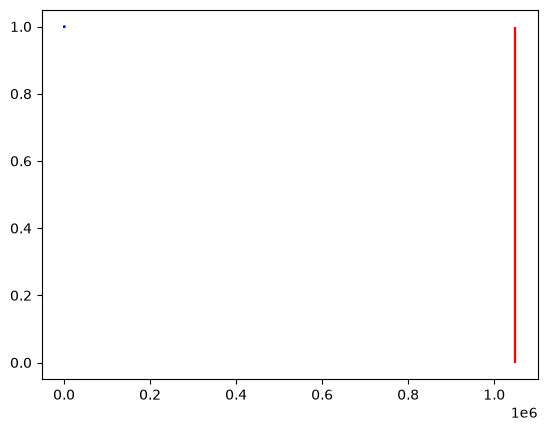

In [57]:
# Plot data
plt.vlines(di.index[di["DI0"]], 0, 1, color = "red")
plt.plot(data.index, data["channel0"]/max(data["channel0"]), color="blue")